# 5. Does a late delivery change what the customer does next?

Notebooks 1 to 4 asked *which orders will be late*. This one asks what lateness **costs**: after a late delivery, is the customer
less likely to order again?

**Why the data can answer it.** A customer chooses the shipping option, so options cannot be compared fairly (First Class is
always late; Same Day depends on the hour). But *inside* Standard Class and Second Class the real delivery time is random: 2 to 6
days, about equally likely each. Two orders with the same option and the same month that differ only in how long the parcel took
are a natural experiment, with no one assigning the delay on purpose.

**Pre-specified before looking at any result**

- **Primary question:** does each extra day of real delivery time (Standard and Second Class, same option and month) change the chance that the customer
  orders again within 90 days of arrival? This is the only test the conclusion rests on.
- **Secondary, not corrected for multiple tests:** 30 and 180 day windows, a late yes/no version, subgroups.
- **What would make it credible:** a balance test (delay is unrelated to order and customer characteristics), a dose-response pattern (more days, more effect),
  and placebo outcomes that cannot be affected by the delay (must be zero).
- **How a null result is reported:** with the smallest effect the data could have detected (80% power), so "no effect" is never claimed
  without saying how small an effect was ruled out.

**Expect to read a null result carefully:** DataCo is synthetic. If its customers' ordering does not depend on delivery, the honest answer is
"no effect", and the interesting part is how precisely we can say so.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import core
from core import CUSTOMER, DATE, MODE, ORDER, PROMISE, TARGET, TARGET_DAYS
pd.set_option("display.width", 170)

raw = core.load_dataco()                       # every order, cancelled ones included
print(f"{len(raw):,} item rows | {raw[ORDER].nunique():,} orders | {raw[CUSTOMER].nunique():,} customers | "
      f"{raw[DATE].min():%Y-%m-%d} to {raw[DATE].max():%Y-%m-%d}")

180,519 item rows | 65,752 orders | 20,652 customers | 2015-01-01 to 2018-01-31


## 1. One row per order

DataCo has one row per *item*; an order with three items appears three times. Everything here is per **order** and per **customer**.
Cancelled orders stay in the table, because a customer who orders again after a cancelled order still ordered again; they are only
excluded as the *delayed* order (a cancelled order was never delivered).

If items of one order disagreed on the shipping option or the real days, taking the first item would be arbitrary. The check below
should show 0 (or very near 0).

In [2]:
display(core.order_consistency(raw).round(4).rename("share of orders whose items disagree"))
orders_all = core.order_table(raw)
shipped = orders_all[~orders_all["cancelled"]]
first_rows = raw.drop_duplicates(ORDER).set_index(ORDER)
agree = (shipped["late"].to_numpy() == first_rows.loc[shipped[ORDER], TARGET].to_numpy()).mean()
print(f"{len(orders_all):,} orders ({len(shipped):,} shipped). Lateness recomputed from days agrees with Late_delivery_risk for {agree:.2%} of shipped orders.")
print("orders per customer:"); display(orders_all.groupby(CUSTOMER).size().describe().round(2))

Shipping Mode                    0.0
Days for shipment (scheduled)    0.0
Days for shipping (real)         0.0
Customer Id                      0.0
Name: share of orders whose items disagree, dtype: float64

65,752 orders (62,897 shipped). Lateness recomputed from days agrees with Late_delivery_risk for 100.00% of shipped orders.
orders per customer:


count    20652.00
mean         3.18
std          2.43
min          1.00
25%          1.00
50%          3.00
75%          5.00
max         15.00
dtype: float64

## 2. The outcome, measured from arrival

A reaction to a late delivery cannot happen before the parcel arrives, so the clock starts at **arrival** (order date plus real days).
For each order, the next order is the customer's first later order placed strictly after arrival; `reorder_W` is 1 if it comes within
W days. An order only counts when the data covers its full window (otherwise it would look like "no reorder" just because the data ended).

In [3]:
orders = core.add_followup(orders_all, windows=(30, 90, 180))
orders["month"] = orders[DATE].dt.to_period("M").astype(str)
orders["hour"], orders["weekday"] = orders[DATE].dt.hour, orders[DATE].dt.weekday
orders["log_value"] = np.log1p(orders["value"])
orders["real_days"] = orders[TARGET_DAYS].astype(float)
ship = orders[~orders["cancelled"]]
pd.DataFrame({f"within {w} days": {"share who order again": ship.loc[ship[f"followup_{w}"], f"reorder_{w}"].mean(),
                                   "orders with full follow-up": int(ship[f"followup_{w}"].sum())} for w in (30, 90, 180)}).T

,share who order again,orders with full follow-up
within 30 days,0.113435,60687.0
within 90 days,0.313092,56766.0
within 180 days,0.539473,51541.0


## 3. Is the delay really random inside an option?

Only Standard and Second Class have variation to use. First Class always takes 2 days; Same Day depends on the order hour, which is a rule
and not luck. If the real days inside the two options are uniform over 2 to 6, and nothing about the order or customer predicts the
delay, the comparison is fair.

In [4]:
print("share of orders by real delivery days:")
display(pd.crosstab(ship[MODE], ship["real_days"], normalize="index").round(3))
for m in ["Standard Class", "Second Class"]:
    seen = ship.loc[ship[MODE] == m, "real_days"].value_counts().sort_index()
    print(f"{m}: days {list(seen.index.astype(int))}, chi-square test against uniform p = {stats.chisquare(seen).pvalue:.3f}")

share of orders by real delivery days:


real_days,0.0,1.0,2.0,3.0,4.0,5.0,6.0
Shipping Mode,,,,,,,
First Class,0.000,0.000,1.000,0.000,0.000,0.000,0.0
Same Day,0.516,0.484,0.000,0.000,0.000,0.000,0.0
Second Class,0.000,0.000,0.200,0.198,0.202,0.200,0.2
Standard Class,0.000,0.000,0.202,0.200,0.200,0.198,0.2


Standard Class: days [2, 3, 4, 5, 6], chi-square test against uniform p = 0.807
Second Class: days [2, 3, 4, 5, 6], chi-square test against uniform p = 0.968


**Balance test.** Inside an option and month, regress the real days on everything known about the order (value, earlier orders, hour,
weekday, segment, market, department) and test whether these are jointly zero. A small p-value would mean the delay is *not* random
and the comparison is biased. Standard errors are clustered by customer.

In [5]:
exp = ship[ship[MODE].isin(["Standard Class", "Second Class"])].copy()
print(f"analysis sample: {len(exp):,} orders from {exp[CUSTOMER].nunique():,} customers")
bal = core.balance_test(exp, "real_days", numeric=["log_value", "prior_orders", "hour", "weekday"],
                        categorical=["segment", "market", "department"], fe=(MODE, "month"))
print(f"balance test: Wald chi-square = {bal['wald']:.1f} on {bal['df']} degrees of freedom, p = {bal['p']:.3f}")
print("p above 0.05: no sign that order characteristics predict the delay. A small p means do not trust the estimates below.")

analysis sample: 49,888 orders from 18,389 customers
balance test: Wald chi-square = 13.1 on 20 degrees of freedom, p = 0.872
p above 0.05: no sign that order characteristics predict the delay. A small p means do not trust the estimates below.


## 4. The estimates

First the **naive** comparison across all shipped orders, which is what a quick analysis would do. It is confounded: late orders are mostly
First Class and Second Class orders, so the comparison mixes the *option* with the *delay*.

Then the **designed** comparison inside Standard and Second Class (option and month held fixed). Effects are in percentage points of the
chance to order again. `smallest detectable` is the effect the data could have found with 80% power: smaller true effects cannot be ruled out.

In [6]:
nv = ship[ship["followup_90"]].groupby("late")["reorder_90"].agg(share_who_order_again="mean", orders="size")
display(nv.round(4))
print(f"naive difference, late minus on time: {100 * (nv.loc[1, 'share_who_order_again'] - nv.loc[0, 'share_who_order_again']):+.2f} points (mixes shipping options)")

rows = []
specs = {"option and month": {}, "plus order controls": dict(numeric=["log_value", "prior_orders"], categorical=["segment", "market", "department"])}
for w in (30, 90, 180):
    sub = exp[exp[f"followup_{w}"]]
    for label, ex in [("each extra day", "real_days"), ("late (yes = 1)", "late")]:
        for spec, kw in specs.items():
            r = core.effect_of_delay(sub, f"reorder_{w}", ex, fe=(MODE, "month"), **kw)
            rows.append({"window": f"{w} days", "exposure": label, "model": spec, "effect (points)": 100 * r["coef"],
                         "95% low": 100 * r["lo"], "95% high": 100 * r["hi"], "p": r["p"],
                         "smallest detectable": 100 * r["mde"], "orders": r["n"], "customers": r["customers"]})
designed = pd.DataFrame(rows)
designed.round(3)

,share_who_order_again,orders
late,,
0,0.3134,24303
1,0.3129,32463


naive difference, late minus on time: -0.05 points (mixes shipping options)


,window,exposure,model,effect (points),95% low,95% high,p,smallest detectable,orders,customers
0,30 days,each extra day,option and month,-0.001,-0.201,0.198,0.989,0.286,48117,16618
1,30 days,each extra day,plus order controls,-0.002,-0.202,0.198,0.983,0.286,48117,16618
2,30 days,late (yes = 1),option and month,-0.205,-0.805,0.395,0.504,0.857,48117,16618
3,30 days,late (yes = 1),plus order controls,-0.208,-0.808,0.393,0.498,0.858,48117,16618
4,90 days,each extra day,option and month,-0.059,-0.358,0.240,0.698,0.427,44991,13492
5,90 days,each extra day,plus order controls,-0.060,-0.359,0.239,0.692,0.427,44991,13492
6,90 days,late (yes = 1),option and month,-0.118,-1.023,0.787,0.799,1.293,44991,13492
7,90 days,late (yes = 1),plus order controls,-0.120,-1.025,0.784,0.794,1.293,44991,13492
8,180 days,each extra day,option and month,0.041,-0.296,0.378,0.812,0.481,40859,11997
9,180 days,each extra day,plus order controls,0.041,-0.296,0.378,0.812,0.481,40859,11997


**The primary result** is the row *90 days, each extra day, option and month*: each extra day of delivery time changes the chance of ordering again within 90 days by **-0.06 points** (95% interval -0.36 to +0.24, p = 0.70). The data could have detected an effect of **0.43 points** per day. The base rate is 31.3%, so a decline larger than 0.36 points per day (about 1.4 points over the four extra days) is ruled out.

## 5. Dose-response

If delay hurts, the damage should grow with the days. The chart shows, for each real delivery time, the change in the chance of ordering
again compared with the shortest delivery (2 days), with 95% intervals.

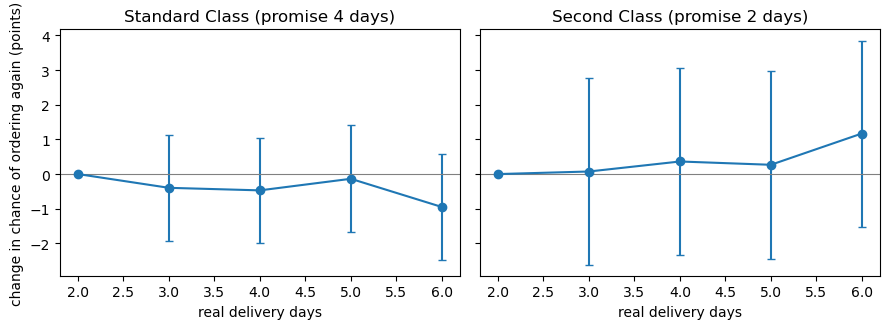

real days  difference      lo      hi  orders
option                                                         
Standard Class 0        2.0      0.0000  0.0000  0.0000    6888
               1        3.0     -0.0040 -0.0193  0.0114    6808
               2        4.0     -0.0047 -0.0198  0.0104    6784
               3        5.0     -0.0014 -0.0168  0.0141    6720
               4        6.0     -0.0095 -0.0249  0.0059    6783
Second Class   0        2.0      0.0000  0.0000  0.0000    2212
               1        3.0      0.0007 -0.0261  0.0276    2178
               2        4.0      0.0036 -0.0233  0.0306    2216
               3        5.0      0.0027 -0.0245  0.0298    2193
               4        6.0      0.0117 -0.0151  0.0385    2209

In [7]:
sub = exp[exp["followup_90"]]
dose = {}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, m in zip(axes, ["Standard Class", "Second Class"]):
    part = sub[sub[MODE] == m]
    dr = core.dose_response(part, "reorder_90", "real_days"); dose[m] = dr
    ax.errorbar(dr["real days"], 100 * dr["difference"], yerr=[100 * (dr["difference"] - dr["lo"]), 100 * (dr["hi"] - dr["difference"])],
                fmt="o-", capsize=3)
    ax.axhline(0, color="grey", lw=.8)
    ax.set(title=f"{m} (promise {int(part[PROMISE].iloc[0])} days)", xlabel="real delivery days")
axes[0].set_ylabel("change in chance of ordering again (points)")
plt.tight_layout(); plt.show()
pd.concat(dose, names=["option"]).round(4)

## 6. Placebo outcomes

These cannot be affected by this order's delivery time: how long ago the customer's *previous* order was, and how many orders they had
before. If the method finds an "effect" on them, the comparison is not fair (or the code has a bug). Both should be about zero.

In [8]:
rows = []
for label, y in [("days since the customer's previous order", "days_since_prev"), ("number of earlier orders", "prior_orders")]:
    r = core.effect_of_delay(exp, y, "real_days", fe=(MODE, "month"))
    rows.append({"placebo outcome": label, "effect per extra day": r["coef"], "95% low": r["lo"], "95% high": r["hi"], "p": r["p"]})
placebo = pd.DataFrame(rows)
placebo.round(4)

,placebo outcome,effect per extra day,95% low,95% high,p
0,days since the customer's previous order,-0.2196,-1.2831,0.8440,0.6858
1,number of earlier orders,-0.0015,-0.0105,0.0075,0.7393


## 7. Does it matter more for some customers?

A first delivery may shape a new customer more than a returning one. These are secondary and not corrected for testing several groups, so
with many groups one small p-value is expected by chance.

In [9]:
sub = exp[exp["followup_90"]]
groups = {"first-time customers (no earlier order)": sub["prior_orders"] == 0, "returning customers": sub["prior_orders"] > 0}
groups.update({f"segment: {s}": sub["segment"] == s for s in sorted(sub["segment"].unique())})
rows = []
for name, mask in groups.items():
    r = core.effect_of_delay(sub[mask], "reorder_90", "real_days", fe=(MODE, "month"))
    rows.append({"group": name, "orders": r["n"], "effect per extra day (points)": 100 * r["coef"], "95% low": 100 * r["lo"],
                 "95% high": 100 * r["hi"], "p": r["p"], "smallest detectable": 100 * r["mde"]})
hetero = pd.DataFrame(rows)
hetero.round(3)

,group,orders,effect per extra day (points),95% low,95% high,p,smallest detectable
0,first-time customers (no earlier order),10793,0.028,-0.559,0.615,0.926,0.839
1,returning customers,34198,-0.085,-0.430,0.260,0.629,0.492
2,segment: Consumer,23323,-0.095,-0.512,0.322,0.655,0.595
3,segment: Corporate,13639,0.219,-0.323,0.760,0.429,0.774
4,segment: Home Office,8029,-0.462,-1.162,0.237,0.195,0.999


## 8. Threats to validity

- **Synthetic data.** If the generator did not link ordering to delivery, a null result is the expected truth, and it says nothing about real customers.
  What the notebook shows is the *method*: how a delay effect is identified and how much precision the data gives.
- **Randomness is only tested, not guaranteed.** The balance test cannot prove the delay is random; it can only fail to find a pattern.
- **Only two options have variation.** Same Day and First Class cannot be used, so the result speaks for Standard and Second Class customers only.
- **Orders placed before arrival are skipped** as outcomes, because they cannot be a reaction. This is on purpose, but it means the outcome is
  "the next order after the parcel arrived".
- **Cancelled orders count as reorders.** Excluding them does not change the question much, but is a choice worth stating.
- **Time windows.** Orders near the end of the data lack a full follow-up window and are excluded; later orders are therefore under-represented.
- **Several tests.** One primary test; everything else is descriptive.

## Findings

1. **Balance:** real days are uniform in both options (chi-square p = 0.81 Standard, 0.97 Second) and order characteristics do not predict the delay (Wald chi-square 13.1 on 20 df, p = 0.87). The delay looks as good as random inside an option.
2. **Primary result:** -0.06 points per extra day on reordering within 90 days (95% interval -0.36 to +0.24, p = 0.70); smallest detectable effect 0.43 points per day. Base rate 31.3%, so declines above 0.36 points per day (about 1.4 points, 4.6% of the base rate, over four extra days) are ruled out. The 30 and 180 day windows also show zero (0.00 and +0.04 points, intervals include zero).
3. **Naive against designed:** naive late minus on time is -0.05 points (31.29% against 31.34%) and the designed late-yes/no estimate is -0.12 (-1.02 to +0.79). Both are about zero, so confounding by shipping option did not matter here.
4. **Dose-response:** no pattern. Standard Class differences against 2 days run from -1.0 to -0.1 points, Second Class from +0.1 to +1.2, every interval includes zero and the options point in opposite directions.
5. **Placebo outcomes:** days since the previous order -0.22 (-1.28 to +0.84) and earlier orders -0.0015 (-0.0105 to +0.0075): both about zero, no sign of bias.
6. **Subgroups:** first-time customers, returning customers and each segment all include zero (smallest p = 0.195, Home Office); with five groups that is unremarkable.

**Conclusion:** in this data a longer delivery inside an option has no detectable effect on reordering, and the data rule out declines larger than 0.36 points per extra day. DataCo is synthetic, so this shows the method and that no such effect is built into the data, not that real customers ignore delays.


## 9. Save the results

In [10]:
import joblib
joblib.dump({"balance": bal, "designed": designed, "dose": dose, "placebo": placebo, "hetero": hetero, "naive": nv},
            core.ROOT / "models" / "customer_impact.joblib")
print("saved models/customer_impact.joblib")

saved models/customer_impact.joblib
